<a href="https://colab.research.google.com/github/samar8x/CVIP_Project/blob/main/Notebooks/03_ACDC_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — ACDC Adverse-Condition Evaluation


This notebook evaluates the same fixed Cityscapes-trained SegFormer-B2 model on the ACDC validation subsets for:

- fog,
- rain,
- snow,
- night.

The model remains unchanged.

Following the ACDC evaluation protocol, this notebook explicitly excludes:

- semantic ignore pixels with label value `255`,
- ACDC invalid/uncertain pixels indicated by `invIds == 1`.

The outputs are:

- condition-wise mIoU,
- per-class IoU for all 19 semantic classes,
- aggregate confusion matrices,
- an audit of how many pixels are excluded by the ACDC invalid/uncertainty masks.

The matched normal-to-adverse analysis is handled later in the matched ACDC notebook.

Mount Drive and restore paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/CV_Project")

DATASETS_DIR = PROJECT_ROOT / "datasets"
CONFIG_DIR = PROJECT_ROOT / "config"
RESULTS_DIR = PROJECT_ROOT / "results"
LOGS_DIR = PROJECT_ROOT / "logs"
MODELS_DIR = PROJECT_ROOT / "models"

print("PROJECT_ROOT:", PROJECT_ROOT)

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/CV_Project


Define ACDC paths

In [ ]:
import zipfile
import numpy as np

LOCAL_DATA_ROOT = Path("/content/cv_data")

ACDC_RGB_ZIP = (
    DATASETS_DIR
    / "acdc"
    / "rgb_anon.zip"
)

ACDC_GT_ZIP = (
    DATASETS_DIR
    / "archives"
    / "gt_trainval.zip"
)

ACDC_RGB_OUT = (
    LOCAL_DATA_ROOT
    / "acdc"
    / "rgb"
)

ACDC_GT_OUT = (
    LOCAL_DATA_ROOT
    / "acdc_gt"
)

ACDC_RGB_OUT.mkdir(
    parents=True,
    exist_ok=True
)

ACDC_GT_OUT.mkdir(
    parents=True,
    exist_ok=True
)

print("ACDC paths ready.")

ACDC paths ready.


Extract only ACDC validation RGB images if needed

In [ ]:
import zipfile
import shutil
from pathlib import Path

conditions = [
    "fog",
    "rain",
    "snow",
    "night",
]


# ------------------------------------------------------------
# Copy ACDC RGB ZIP from Drive to local Colab storage
# ------------------------------------------------------------

LOCAL_ACDC_RGB_ZIP = Path(
    "/content/rgb_anon.zip"
)

if not LOCAL_ACDC_RGB_ZIP.exists():

    print(
        "Copying ACDC RGB ZIP "
        "from Drive to local storage..."
    )

    shutil.copy2(
        ACDC_RGB_ZIP,
        LOCAL_ACDC_RGB_ZIP
    )

    print(
        "Local ZIP copy complete."
    )

else:

    print(
        "Local ACDC RGB ZIP already exists."
    )


# ------------------------------------------------------------
# Check existing validation images
# ------------------------------------------------------------

existing_val_images = list(
    ACDC_RGB_OUT.rglob("*.png")
)

val_images_only = [
    p
    for p in existing_val_images
    if "/val/" in str(p)
]

print(
    "Existing validation RGB images:",
    len(val_images_only)
)


# ------------------------------------------------------------
# Extract validation RGB images
# ------------------------------------------------------------

if len(val_images_only) == 406:

    print(
        "ACDC validation RGB already prepared."
    )

else:

    print(
        "Extracting ACDC validation RGB images..."
    )

    with zipfile.ZipFile(
        LOCAL_ACDC_RGB_ZIP,
        "r"
    ) as z:

        selected = []

        for name in z.namelist():

            if "__MACOSX" in name:
                continue

            if not name.endswith(".png"):
                continue

            parts = name.split("/")

            if len(parts) < 5:
                continue

            root = parts[0]
            condition = parts[1]
            split = parts[2]

            if (
                root == "rgb_anon"
                and condition in conditions
                and split == "val"
            ):
                selected.append(name)

        print(
            "Selected images:",
            len(selected)
        )

        for i, name in enumerate(
            selected,
            start=1
        ):

            z.extract(
                name,
                ACDC_RGB_OUT
            )

            if (
                i % 100 == 0
                or i == len(selected)
            ):

                print(
                    f"{i}/{len(selected)}"
                )

    print(
        "RGB extraction complete."
    )


# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

final_val_images = [
    p
    for p in ACDC_RGB_OUT.rglob("*.png")
    if "/val/" in str(p)
]

print(
    "Final ACDC validation RGB count:",
    len(final_val_images)
)

assert len(final_val_images) == 406

print(
    "✓ ACDC validation RGB verified."
)

Copying ACDC RGB ZIP from Drive to local storage...
Local ZIP copy complete.
Existing validation RGB images: 0
Extracting ACDC validation RGB images...
Selected images: 406
100/406
200/406
300/406
400/406
406/406
RGB extraction complete.
Final ACDC validation RGB count: 406
✓ ACDC validation RGB verified.


Extract ACDC validation semantic GT and invalid/uncertainty masks

In [ ]:
existing_gt = list(
    ACDC_GT_OUT.rglob(
        "*_gt_labelTrainIds.png"
    )
)

existing_invalid = list(
    ACDC_GT_OUT.rglob(
        "*_gt_invIds.png"
    )
)

val_gt_only = [
    p for p in existing_gt
    if "/val/" in str(p)
]

val_invalid_only = [
    p for p in existing_invalid
    if "/val/" in str(p)
]

if (
    len(val_gt_only) == 406
    and len(val_invalid_only) == 406
):

    print(
        "ACDC validation GT and "
        "invIds already prepared."
    )

else:

    print(
        "Extracting ACDC validation "
        "GT and invIds..."
    )

    with zipfile.ZipFile(
        ACDC_GT_ZIP,
        "r"
    ) as z:

        selected_gt = [
            name
            for name in z.namelist()

            if "/val/" in name

            and name.endswith(
                "_gt_labelTrainIds.png"
            )

            and "__MACOSX" not in name
        ]

        selected_invalid = [
            name
            for name in z.namelist()

            if "/val/" in name

            and name.endswith(
                "_gt_invIds.png"
            )

            and "__MACOSX" not in name
        ]

        print(
            "Selected GT masks:",
            len(selected_gt)
        )

        print(
            "Selected invIds masks:",
            len(selected_invalid)
        )

        selected_all = (
            selected_gt
            + selected_invalid
        )

        for i, name in enumerate(
            selected_all,
            start=1
        ):

            z.extract(
                name,
                ACDC_GT_OUT
            )

            if (
                i % 100 == 0
                or i == len(selected_all)
            ):

                print(
                    f"{i}/{len(selected_all)}"
                )

    print(
        "GT and invIds extraction complete."
    )

Extracting ACDC validation GT and invIds...
Selected GT masks: 406
Selected invIds masks: 406
100/812
200/812
300/812
400/812
500/812
600/812
700/812
800/812
812/812
GT and invIds extraction complete.


Build condition-wise image lists

In [ ]:
ACDC_RGB_ROOT = (
    ACDC_RGB_OUT
    / "rgb_anon"
)

condition_images = {}

for condition in conditions:

    folder = (
        ACDC_RGB_ROOT
        / condition
        / "val"
    )

    files = sorted(
        folder.rglob("*.png")
    )

    condition_images[condition] = files

    print(
        f"{condition:5}: "
        f"{len(files)} RGB images"
    )

fog  : 100 RGB images
rain : 100 RGB images
snow : 100 RGB images
night: 106 RGB images


Build GT and invalid-mask lookups

In [ ]:
acdc_gt_files = sorted(
    ACDC_GT_OUT.rglob(
        "*_gt_labelTrainIds.png"
    )
)

acdc_invalid_files = sorted(
    ACDC_GT_OUT.rglob(
        "*_gt_invIds.png"
    )
)

gt_lookup = {}
invalid_lookup = {}

for gt_path in acdc_gt_files:

    if "/val/" not in str(gt_path):
        continue

    key = (
        gt_path.name
        .replace(
            "_gt_labelTrainIds.png",
            ""
        )
    )

    gt_lookup[key] = gt_path


for invalid_path in acdc_invalid_files:

    if "/val/" not in str(invalid_path):
        continue

    key = (
        invalid_path.name
        .replace(
            "_gt_invIds.png",
            ""
        )
    )

    invalid_lookup[key] = (
        invalid_path
    )


print(
    "GT lookup entries:",
    len(gt_lookup)
)

print(
    "invIds lookup entries:",
    len(invalid_lookup)
)

GT lookup entries: 406
invIds lookup entries: 406


Verify RGB ↔ GT ↔ invIds matching

In [ ]:
missing_gt = []
missing_invalid = []

total_rgb = 0

for condition in conditions:

    for image_path in condition_images[condition]:

        total_rgb += 1

        key = (
            image_path.name
            .replace(
                "_rgb_anon.png",
                ""
            )
        )

        if key not in gt_lookup:
            missing_gt.append(
                image_path
            )

        if key not in invalid_lookup:
            missing_invalid.append(
                image_path
            )


print(
    "Total RGB images:",
    total_rgb
)

print(
    "Missing GT masks:",
    len(missing_gt)
)

print(
    "Missing invIds masks:",
    len(missing_invalid)
)

assert len(missing_gt) == 0
assert len(missing_invalid) == 0

print(
    "RGB, GT and invIds matching verified."
)

Total RGB images: 406
Missing GT masks: 0
Missing invIds masks: 0
RGB, GT and invIds matching verified.


Install/import model libraries

In [ ]:
!pip -q install transformers

In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from transformers import (
    AutoImageProcessor,
    SegformerForSemanticSegmentation
)

import torch.nn.functional as F

print("PyTorch:", torch.__version__)
print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Load model

In [ ]:
DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

MODEL_NAME = (
    "nvidia/"
    "segformer-b2-finetuned-"
    "cityscapes-1024-1024"
)

processor = (
    AutoImageProcessor
    .from_pretrained(MODEL_NAME)
)

model = (
    SegformerForSemanticSegmentation
    .from_pretrained(MODEL_NAME)
)

model = model.to(DEVICE)
model.eval()

print("Using device:", DEVICE)
print("Model loaded.")

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

Using device: cuda
Model loaded.


Define class names

In [ ]:
CLASS_NAMES = [
    "road",
    "sidewalk",
    "building",
    "wall",
    "fence",
    "pole",
    "traffic light",
    "traffic sign",
    "vegetation",
    "terrain",
    "sky",
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle",
]

NUM_CLASSES = 19
IGNORE_INDEX = 255

Confusion matrix helper with ACDC invalid-mask handling

In [ ]:
def update_confusion_matrix(
    confusion_matrix,
    ground_truth,
    prediction,
    invalid_mask=None,
    num_classes=NUM_CLASSES
):

    valid_mask = (
        (ground_truth != IGNORE_INDEX)
        & (ground_truth >= 0)
        & (ground_truth < num_classes)
    )

    # ACDC invIds convention:
    # 0 = valid pixel
    # 1 = invalid / uncertain pixel
    if invalid_mask is not None:

        if (
            invalid_mask.shape
            != ground_truth.shape
        ):
            raise ValueError(
                "GT and invIds shapes do not match: "
                f"{ground_truth.shape} vs "
                f"{invalid_mask.shape}"
            )

        valid_mask &= (
            invalid_mask == 0
        )

    gt = ground_truth[
        valid_mask
    ]

    pred = prediction[
        valid_mask
    ]

    valid_pred = (
        (pred >= 0)
        & (pred < num_classes)
    )

    gt = gt[
        valid_pred
    ]

    pred = pred[
        valid_pred
    ]

    indices = (
        num_classes
        * gt.astype(np.int64)
        + pred.astype(np.int64)
    )

    bincount = np.bincount(
        indices,
        minlength=num_classes ** 2
    )

    confusion_matrix += (
        bincount.reshape(
            num_classes,
            num_classes
        )
    )

    return confusion_matrix

IoU helper

In [ ]:
def calculate_iou(
    confusion_matrix
):

    intersection = np.diag(
        confusion_matrix
    )

    gt_total = (
        confusion_matrix.sum(
            axis=1
        )
    )

    pred_total = (
        confusion_matrix.sum(
            axis=0
        )
    )

    union = (
        gt_total
        + pred_total
        - intersection
    )

    iou = np.full(
        NUM_CLASSES,
        np.nan,
        dtype=np.float64
    )

    valid = union > 0

    iou[valid] = (
        intersection[valid]
        / union[valid]
    )

    return iou

Test ONE ACDC image first

In [ ]:
sample_condition = "fog"

sample_image_path = (
    condition_images[
        sample_condition
    ][0]
)

print(sample_image_path)

/content/cv_data/acdc/rgb/rgb_anon/fog/val/GOPR0476/GOPR0476_frame_000761_rgb_anon.png


In [ ]:
image = Image.open(
    sample_image_path
).convert("RGB")

image_key = (
    sample_image_path.name
    .replace(
        "_rgb_anon.png",
        ""
    )
)

gt_path = (
    gt_lookup[
        image_key
    ]
)

invalid_path = (
    invalid_lookup[
        image_key
    ]
)

gt_trainids = np.array(
    Image.open(
        gt_path
    )
)

invalid_mask = np.array(
    Image.open(
        invalid_path
    )
)

print(
    "Image size:",
    image.size
)

print(
    "GT shape:",
    gt_trainids.shape
)

print(
    "invIds shape:",
    invalid_mask.shape
)

print(
    "GT IDs:",
    np.unique(
        gt_trainids
    )
)

print(
    "invIds values:",
    np.unique(
        invalid_mask
    )
)

print(
    "Invalid / uncertain pixels:",
    int(
        (
            invalid_mask == 1
        ).sum()
    )
)

Image size: (1920, 1080)
GT shape: (1080, 1920)
invIds shape: (1080, 1920)
GT IDs: [  0   1   2   4   5   6   7  10  13 255]
invIds values: [0 1]
Invalid / uncertain pixels: 118752


Run one prediction

In [ ]:
inputs = processor(
    images=image,
    return_tensors="pt"
)

pixel_values = (
    inputs["pixel_values"]
    .to(DEVICE)
)

with torch.inference_mode():

    outputs = model(
        pixel_values=pixel_values
    )

upsampled_logits = F.interpolate(
    outputs.logits,

    size=gt_trainids.shape,

    mode="bilinear",

    align_corners=False
)

prediction = (
    upsampled_logits
    .argmax(dim=1)[0]
    .cpu()
    .numpy()
)

print(
    "Prediction shape:",
    prediction.shape
)

print(
    "GT shape:",
    gt_trainids.shape
)

print(
    "Predicted IDs:",
    np.unique(prediction)
)

Prediction shape: (1080, 1920)
GT shape: (1080, 1920)
Predicted IDs: [ 0  1  2  4  5  6  7 10 11 13 14 18]


Visualize one adverse example

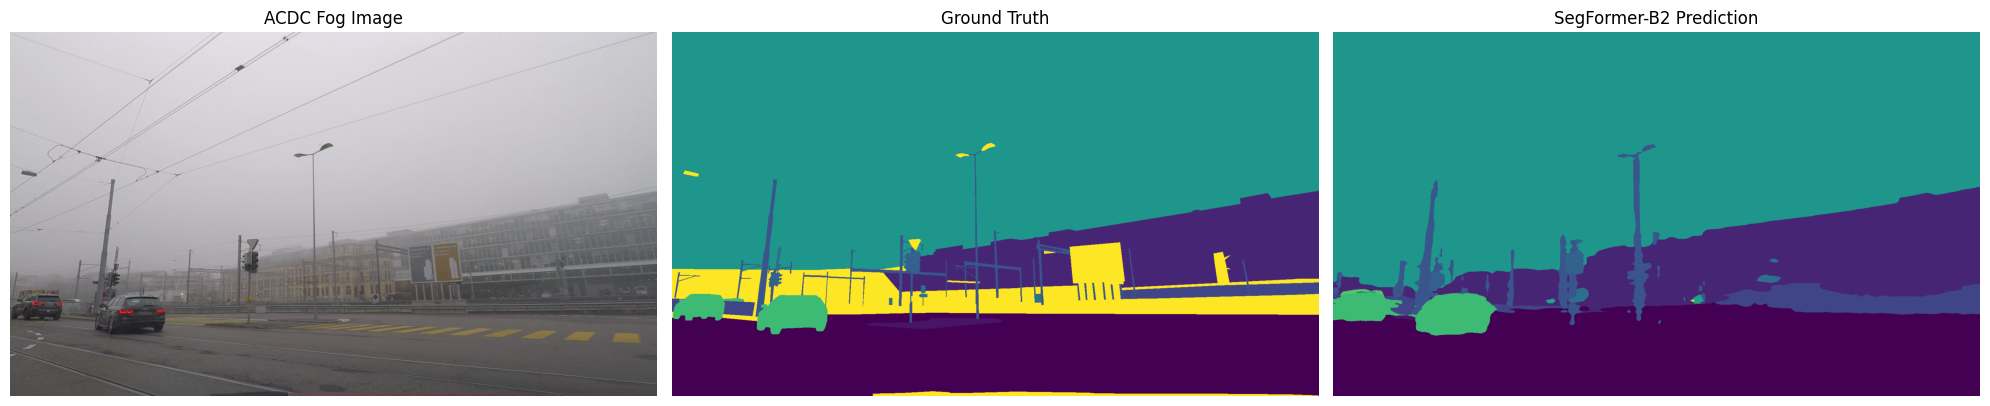

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 7)
)

axes[0].imshow(image)
axes[0].set_title(
    f"ACDC {sample_condition.title()} Image"
)
axes[0].axis("off")

gt_display = (
    gt_trainids.copy()
)

gt_display[
    gt_display == 255
] = 19

axes[1].imshow(
    gt_display,
    vmin=0,
    vmax=19
)

axes[1].set_title(
    "Ground Truth"
)

axes[1].axis("off")

axes[2].imshow(
    prediction,
    vmin=0,
    vmax=19
)

axes[2].set_title(
    "SegFormer-B2 Prediction"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()

## ACDC Invalid/Uncertainty-Mask Audit

Before evaluation, count how many pixels are excluded by the ACDC `invIds` masks for each condition. These pixels are not allowed to contribute to TP, FP, FN, IoU, or mIoU.

In [ ]:
mask_audit_rows = []

for condition in conditions:

    total_pixels = 0
    semantic_valid_pixels = 0
    invalid_pixels = 0
    final_valid_pixels = 0

    for image_path in condition_images[
        condition
    ]:

        key = (
            image_path.name
            .replace(
                "_rgb_anon.png",
                ""
            )
        )

        gt = np.array(
            Image.open(
                gt_lookup[
                    key
                ]
            )
        )

        inv = np.array(
            Image.open(
                invalid_lookup[
                    key
                ]
            )
        )

        semantic_valid = (
            (gt != IGNORE_INDEX)
            & (gt >= 0)
            & (gt < NUM_CLASSES)
        )

        invalid = (
            inv == 1
        )

        final_valid = (
            semantic_valid
            & (~invalid)
        )

        total_pixels += (
            gt.size
        )

        semantic_valid_pixels += int(
            semantic_valid.sum()
        )

        invalid_pixels += int(
            invalid.sum()
        )

        final_valid_pixels += int(
            final_valid.sum()
        )

    mask_audit_rows.append({
        "condition":
            condition,

        "num_images":
            len(
                condition_images[
                    condition
                ]
            ),

        "total_pixels":
            total_pixels,

        "semantic_valid_pixels":
            semantic_valid_pixels,

        "invalid_uncertain_pixels":
            invalid_pixels,

        "pixels_used_for_iou":
            final_valid_pixels,

        "invalid_percent":
            (
                100
                * invalid_pixels
                / total_pixels
            )
    })


mask_audit = pd.DataFrame(
    mask_audit_rows
)

mask_audit

,condition,num_images,total_pixels,semantic_valid_pixels,invalid_uncertain_pixels,pixels_used_for_iou,invalid_percent
0,fog,100,207360000,196154002,7401770,194522518,3.569526
1,rain,100,207360000,196479419,5528688,195307965,2.666227
2,snow,100,207360000,195643365,6914594,193740033,3.334584
3,night,106,219801600,202435226,86335677,130447366,39.278912


Evaluate one condition function

In [ ]:
from tqdm.auto import tqdm

def evaluate_condition(
    condition_name,
    image_paths
):

    confusion_matrix = np.zeros(
        (
            NUM_CLASSES,
            NUM_CLASSES
        ),
        dtype=np.int64
    )

    for image_path in tqdm(
        image_paths,
        desc=f"Evaluating {condition_name}"
    ):

        # Load image
        image = Image.open(
            image_path
        ).convert("RGB")

        # Find GT and invIds
        image_key = (
            image_path.name
            .replace(
                "_rgb_anon.png",
                ""
            )
        )

        gt_path = (
            gt_lookup[
                image_key
            ]
        )

        invalid_path = (
            invalid_lookup[
                image_key
            ]
        )

        gt_trainids = np.array(
            Image.open(
                gt_path
            )
        )

        invalid_mask = np.array(
            Image.open(
                invalid_path
            )
        )

        # Preprocess
        inputs = processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = (
            inputs["pixel_values"]
            .to(DEVICE)
        )

        # Inference
        with torch.inference_mode():

            outputs = model(
                pixel_values=pixel_values
            )

        # Resize logits
        logits = F.interpolate(
            outputs.logits,

            size=gt_trainids.shape,

            mode="bilinear",

            align_corners=False
        )

        # Prediction
        prediction = (
            logits
            .argmax(dim=1)[0]
            .cpu()
            .numpy()
        )

        # Update confusion matrix.
        # Pixels with GT = 255 or invIds = 1
        # are excluded from the metric.
        confusion_matrix = (
            update_confusion_matrix(
                confusion_matrix,
                gt_trainids,
                prediction,
                invalid_mask=invalid_mask
            )
        )

    iou = calculate_iou(
        confusion_matrix
    )

    miou = np.nanmean(
        iou
    )

    return (
        confusion_matrix,
        iou,
        miou
    )

Evaluate all four conditions

In [ ]:
all_results = {}

for condition in conditions:

    print(
        "\n" + "=" * 60
    )

    print(
        "Condition:",
        condition.upper()
    )

    print(
        "=" * 60
    )

    confusion_matrix, iou, miou = (
        evaluate_condition(
            condition,
            condition_images[
                condition
            ]
        )
    )

    all_results[condition] = {
        "confusion_matrix":
            confusion_matrix,

        "iou":
            iou,

        "miou":
            miou,
    }

    print(
        f"{condition} mIoU: "
        f"{miou:.4f}"
    )


Condition: FOG


Evaluating fog:   0%|          | 0/100 [00:00<?, ?it/s]

fog mIoU: 0.6967

Condition: RAIN


Evaluating rain:   0%|          | 0/100 [00:00<?, ?it/s]

rain mIoU: 0.5002

Condition: SNOW


Evaluating snow:   0%|          | 0/100 [00:00<?, ?it/s]

snow mIoU: 0.4875

Condition: NIGHT


Evaluating night:   0%|          | 0/106 [00:00<?, ?it/s]

night mIoU: 0.3294


Print all per-class results

In [ ]:
for condition in conditions:

    print(
        "\n" + "=" * 70
    )

    print(
        condition.upper()
    )

    print(
        "=" * 70
    )

    iou = (
        all_results[
            condition
        ]["iou"]
    )

    for class_id, class_name in enumerate(
        CLASS_NAMES
    ):

        print(
            f"{class_id:2d} "
            f"{class_name:15s}: "
            f"{iou[class_id]:.4f}"
        )

    print()

    print(
        f"mIoU: "
        f"{all_results[condition]['miou']:.4f}"
    )


FOG
 0 road           : 0.9356
 1 sidewalk       : 0.7400
 2 building       : 0.8168
 3 wall           : 0.5424
 4 fence          : 0.5081
 5 pole           : 0.5427
 6 traffic light  : 0.6856
 7 traffic sign   : 0.6095
 8 vegetation     : 0.8556
 9 terrain        : 0.5042
10 sky            : 0.9644
11 person         : 0.4131
12 rider          : 0.6622
13 car            : 0.8525
14 truck          : 0.6616
15 bus            : 0.9524
16 train          : 0.8952
17 motorcycle     : 0.6636
18 bicycle        : 0.4329

mIoU: 0.6967

RAIN
 0 road           : 0.8276
 1 sidewalk       : 0.3202
 2 building       : 0.8329
 3 wall           : 0.2063
 4 fence          : 0.2538
 5 pole           : 0.4120
 6 traffic light  : 0.6578
 7 traffic sign   : 0.5291
 8 vegetation     : 0.8868
 9 terrain        : 0.4784
10 sky            : 0.9670
11 person         : 0.4855
12 rider          : 0.0000
13 car            : 0.8191
14 truck          : 0.5345
15 bus            : 0.4763
16 train          : 0.2588
17 

Create one combined result table

In [ ]:
results_table = pd.DataFrame({
    "class_id":
        list(range(NUM_CLASSES)),

    "class_name":
        CLASS_NAMES,
})

for condition in conditions:

    results_table[
        f"{condition}_iou"
    ] = (
        all_results[
            condition
        ]["iou"]
    )

results_table

,class_id,class_name,fog_iou,rain_iou,snow_iou,night_iou
0,0,road,0.935619,0.827644,0.760996,0.781753
1,1,sidewalk,0.740026,0.320248,0.284740,0.184372
2,2,building,0.816779,0.832880,0.756327,0.798537
3,3,wall,0.542362,0.206293,0.268669,0.281608
4,4,fence,0.508056,0.253767,0.359533,0.323911
5,5,pole,0.542658,0.412011,0.392716,0.447768
6,6,traffic light,0.685615,0.657814,0.643564,0.406088
7,7,traffic sign,0.609482,0.529138,0.511607,0.213859
8,8,vegetation,0.855644,0.886785,0.807798,0.713910
9,9,terrain,0.504168,0.478352,0.087759,0.171628


Create condition summary

In [ ]:
condition_summary = pd.DataFrame({
    "condition":
        conditions,

    "num_images": [
        len(
            condition_images[c]
        )
        for c in conditions
    ],

    "mIoU": [
        all_results[c]["miou"]
        for c in conditions
    ]
})

condition_summary

,condition,num_images,mIoU
0,fog,100,0.696746
1,rain,100,0.500153
2,snow,100,0.487536
3,night,106,0.329382


Save to Drive

In [ ]:
ACDC_RESULTS_DIR = (
    RESULTS_DIR / "acdc"
)

ACDC_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

results_table.to_csv(
    ACDC_RESULTS_DIR
    / "acdc_per_class_iou.csv",

    index=False
)

condition_summary.to_csv(
    ACDC_RESULTS_DIR
    / "acdc_condition_summary.csv",

    index=False
)

mask_audit.to_csv(
    ACDC_RESULTS_DIR
    / "acdc_invalid_mask_audit.csv",

    index=False
)

print(
    "Saved corrected ACDC results "
    "and invalid-mask audit."
)

Saved corrected ACDC results and invalid-mask audit.


Save the confusion matrices

In [ ]:
for condition in conditions:

    np.save(
        ACDC_RESULTS_DIR
        / f"{condition}_confusion_matrix.npy",

        all_results[
            condition
        ]["confusion_matrix"]
    )

print("ACDC results saved to:")
print(ACDC_RESULTS_DIR)

ACDC results saved to:
/content/drive/MyDrive/CV_Project/results/acdc


Plot condition mIoU

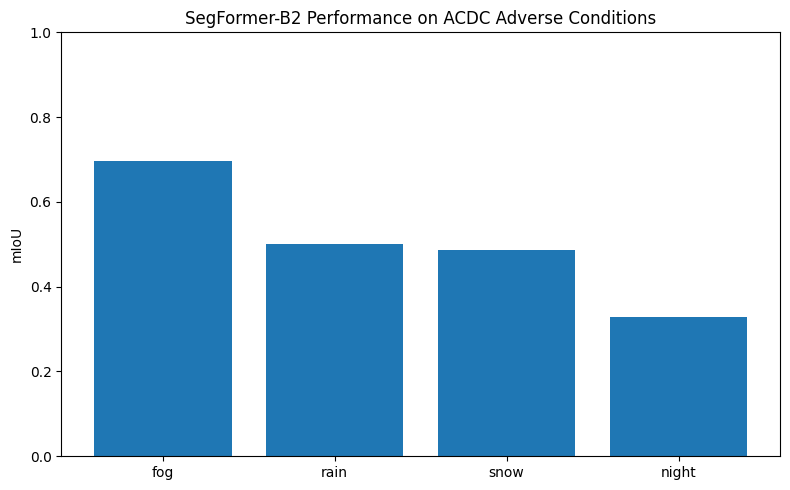

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.bar(
    condition_summary[
        "condition"
    ],

    condition_summary[
        "mIoU"
    ]
)

plt.ylabel("mIoU")

plt.title(
    "SegFormer-B2 Performance on ACDC Adverse Conditions"
)

plt.ylim(
    0,
    1
)

plt.tight_layout()
plt.show()